# Digital Communication: Workshop on Wireless Channels

Adapted from NVIDIA’s [Sionna, v2.2.0](https://nvlabs.github.io/sionna/index.html).

## Basics and imports

Ray tracing is a technique to simulate environment-specific and physically accurate channel realizations for a given scene and user position.

Sionna RT is a open-source hardware-accelerated differentiable ray tracer for radio propagation modeling which is built on top of [Mitsuba 3](https://www.mitsuba-renderer.org/). Mitsuba 3 is a rendering system for forward and inverse light-transport simulation that makes use of the differentiable just-in-time compiler [Dr.Jit](https://drjit.readthedocs.io/en/latest/).

In [16]:
# Import sionna and some of its relevant components
import sionna.rt
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera, PathSolver

# Import packages for this notebook to work
%matplotlib inline
import matplotlib.pyplot as plt
import mitsuba as mi
import numpy as np
from pathlib import Path

no_preview = False # Toggle to False to use the preview widget

# Query the Mitsuba variant that was automatically selected by Sionna RT.
# There should be no need to adjust it, but if you do, make sure to select
# a variant ending in `*_ad_mono_polarized`.
print(f"Mitsuba variant: {mi.variant()}")

Mitsuba variant: cuda_ad_mono_polarized


## Loading and Visualizing Scenes

Sionna RT can either load external scene files (in Mitsuba's XML file format) or it can load one of the [integrated scenes](https://nvlabs.github.io/sionna/rt/api/scene.html#examples).

In this example, we load an example scene containing central Florence, Italy.

In [17]:
# Load the integrated Florence scene
carrier_frequency = 3e9  # Hz
scene_florence = load_scene(sionna.rt.scene.florence, merge_shapes=True)
scene_florence.frequency = carrier_frequency

To visualize the scene, we can use the `preview` function which opens an interactive preview of the scene.
This only works in Jupyter notebooks.

You can use the following controls:

- Mouse left: Rotate
- Scroll wheel: Zoom
- Mouse right (or Ctrl+Left): Move
- Alt+Click: select a point to retrieve coordinates

Please note that only one preview instance per scene can be opened at the same time.
However, multiple scenes can be loaded in parallel.

In [18]:
if not no_preview:
    scene_florence.preview();

It is often convenient to choose a viewpoint in the 3D preview prior to rendering it as a high-quality image.
The next cell uses the "preview" camera which corresponds to the viewpoint of the current preview image.

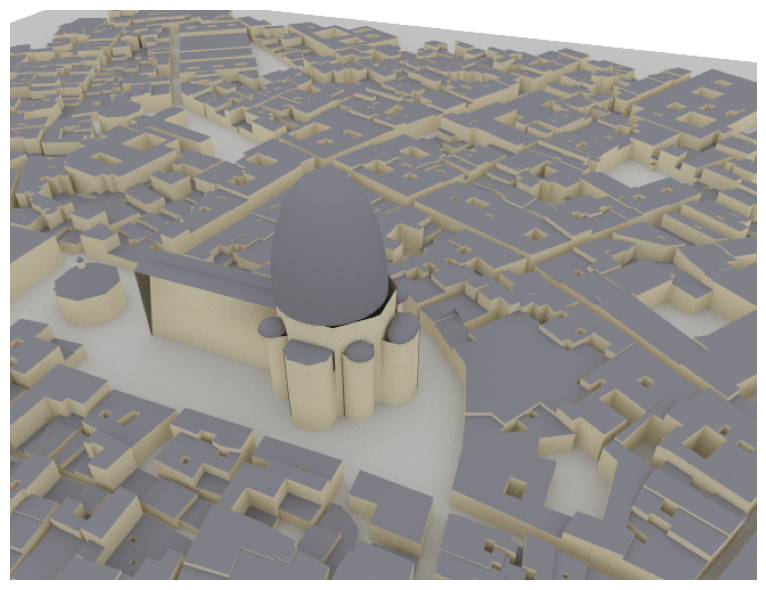

In [20]:
# Only available if a preview is open
if not no_preview:
    scene_florence.render(camera="preview", num_samples=512);

Instead of the preview camera, one can also specify dedicated cameras with different positions and `look_at` directions.

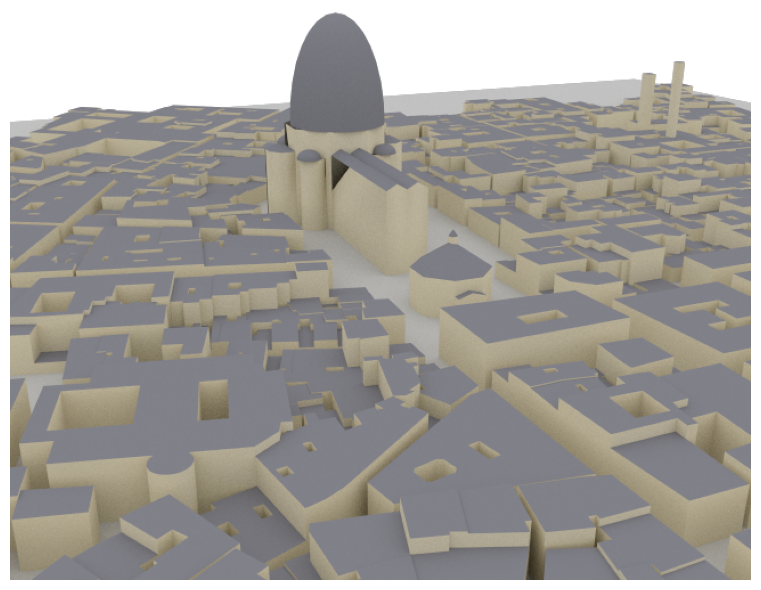

In [21]:
# Create new camera with different configuration
my_cam = Camera(position=[-350,150,150], look_at=[0,0,0])

# Render scene_florence with new camera*
scene_florence.render(camera=my_cam, resolution=[650, 500], num_samples=512); # Increase num_samples to increase image quality

### Let us try to load a custom Pisa scene

Scene files for Mitsuba 3 can be created, edited, and exported with the popular open-source 3D creation suite [Blender](https://www.blender.org/) and the [Mitsuba-Blender add-on](https://github.com/mitsuba-renderer/mitsuba-blender). One can rapdily create scenes from almost any place in the world using [OpenStreetMap](https://www.openstreetmap.org/) and the [Blender-OSM add-on](https://prochitecture.gumroad.com/l/blender-osm). In Sionna, scenes and radio propagation paths can be either rendered through the lens of configurable cameras via ray tracing or displayed with an integrated 3D viewer. For more detail on scene creation and rendering, check [Sionna RT's API documentation](https://nvlabs.github.io/sionna/rt/api/rt.html) and the available [video tutorial](https://youtu.be/7xHLDxUaQ7c).

Set `pisa_scene_file` to the XML file exported from Blender/Mitsuba that is in `scenes` subfolder. Then, write the small piece of code below to preview the Pisa scene, move the camera in a desired position and render the image.

In [22]:
pisa_scene_file = None
scene_pisa = None
if pisa_scene_file is not None:
    pisa_scene_file = Path(pisa_scene_file)
    if not pisa_scene_file.is_file():
        raise FileNotFoundError(pisa_scene_file)
    scene_pisa = load_scene(str(pisa_scene_file), merge_shapes=True)
    scene_pisa.frequency = carrier_frequency
else:
    print("Pisa scene not configured; continuing with Florence.")

Pisa scene not configured; continuing with Florence.


## Ray tracing of Propagation Paths

Once a scene is loaded, we can place Transmitters and Receivers in it and compute propagation paths between them.

For simplicity, all transmitters and all receivers are equipped with the same antenna arrays which are set through the scene properties `scene_*.tx_array` and `scene_*.rx_array`, respectively. Antenna arrays are composed of multiple identical antennas. Antennas can have custom or pre-defined patterns and are either single- or dual-polarized. A scene can contain multiple transmitters and receivers as long as they have unique names.

If needed, more details on antenna patterns can be found in the Developer Guide [Understanding Radio Materials](https://nvlabs.github.io/sionna/rt/developer/dev_custom_radio_materials.html). In the following block, **try to change some parameters to see what it changes**.

(<Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 1 Axes>,
 <Figure size 640x480 with 2 Axes>)

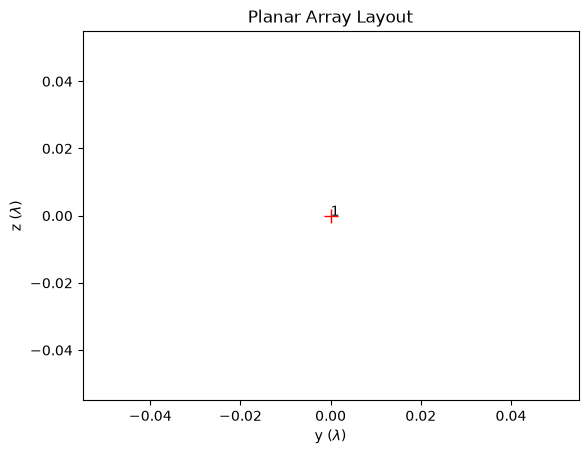

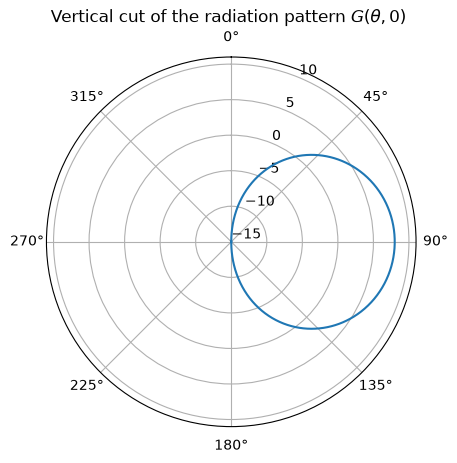

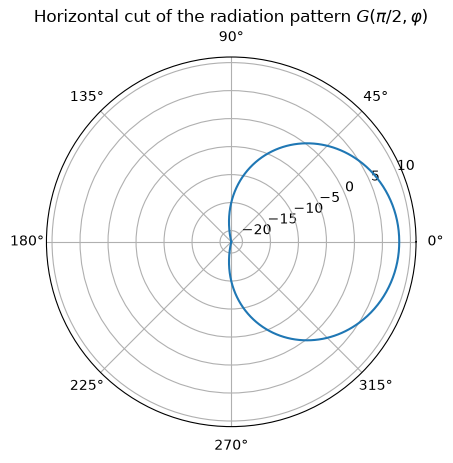

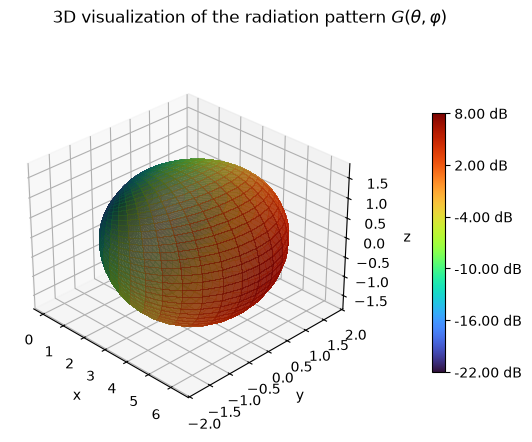

In [40]:
# TX and Rx array definition. Wavelength is set when setting scene_*.frequency
tx_array = PlanarArray(num_rows=1,
                         num_cols=1,
                         vertical_spacing=0.5,     # Half-wavelength spacing
                         horizontal_spacing=0.5,   # Half-wavelength spacing
                         pattern="tr38901",        # 3GPP compliant model. Other model are "iso", "dipole"
                         polarization="V")         # Vertical polarization

rx_array =  PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="dipole",
                             polarization="V")

tx_array.show()
tx_array.antenna_pattern.show()

Now, **go back** to the previously previewed scene; **take the coordinate** of two points of your choice with Alt+Left Click; **set these values as tx_position and rx_position** before running the next block.

In [107]:
# Configure the Florence link (coordinates in meters).
tx_position = [-22, -23, 3]   # x, y, z
rx_position = [44, -2, 1.5]     # x, y, z

# Configure antenna array for all transmitters
scene_florence.tx_array = tx_array

# Configure antenna array for all receivers
scene_florence.rx_array = rx_array

# Remove the previously positioned radio devices
for dev in ["tx", "rx"]:
    scene_florence.remove(dev)

# Create transmitter
tx = Transmitter(name="tx",
                 position=tx_position,
                 display_radius=2)

# Add transmitter instance to scene_florence
scene_florence.add(tx)

# Create a receiver
rx = Receiver(name="rx",
              position=rx_position,
              display_radius=2)

# Add receiver instance to scene_florence
scene_florence.add(rx)

tx.look_at(rx) # Transmitter points towards receiver
rx.look_at(tx) # Receiver points towards transmitter

Propagation paths are computed with the help of a [PathSolver](https://nvlabs.github.io/sionna/rt/api/paths_solvers.html).
The next cell shows how such a path solver is used. 

The parameter `max_depth` determines the maximum number of interactions between a ray and a scene objects. 
For example, with a `max_depth` of zero, only LoS paths are considered. For a `max_depth` of one, LoS as well as first-order reflections of refractions are considered.  When the argument `synthetic_array` is set to `False`, antenna arrays are explicitly modeled by finding paths between any pair of transmitting and receiving antennas in the scene. Otherwise, arrays are represented by a single antenna located in the center of the array and phase shifts related to the relative antenna positions are applied based on a plane-wave assumption.

In [58]:
# Instantiate a path solver
# The same path solver can be used with multiple scenes
p_solver  = PathSolver()

# Compute propagation paths
paths_florence = p_solver(scene=scene_florence,
                         max_depth=5,
                         los=True,
                         specular_reflection=True,
                         diffuse_reflection=False,
                         refraction=True,
                         synthetic_array=False,
                         seed=41)

The [Paths](https://nvlabs.github.io/sionna/rt/paths.html) object contains all paths that have been found between transmitters and receivers.
In principle, the existence of each path is deterministic for a given position and environment. By default, however, `PathSolver` does not guarantee deterministic results, even when `seed` is fixed. Use `PathSolver(deterministic=True)` when deterministic results are required.

**Let us now visualize** the paths in the scene: move the interactive preview in a way to see the paths in the following block. Then, run the block below to have a rendered image (useful to compare with following rendered scenes)

In [108]:
if no_preview:
    scene_florence.render(camera=my_cam, paths=paths_florence, clip_at=100);
else:
    scene_florence.preview(paths=paths_florence, clip_at=100);

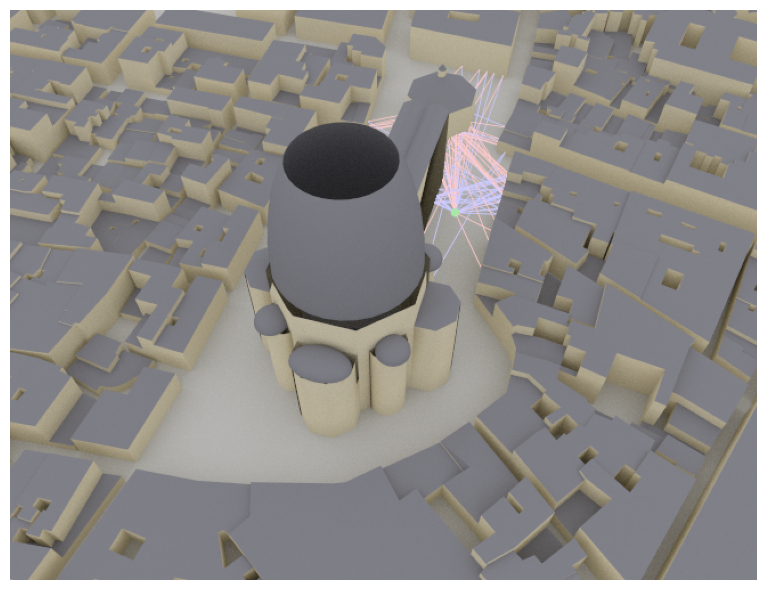

In [109]:
scene_florence.render(camera="preview", paths=paths_florence, num_samples=512, clip_at=100);

The Paths object contains detailed information about every found path and allows us to generate channel impulse responses and apply Doppler shifts for the simulation of time evolution.

### Trace the custom Pisa scene

The same `p_solver` instance can trace a different scene. Fill in the following code setting tx and rx arrays, position of transmitter and receiver and generate the paths as `paths_pisa`. Visualize the scene.

In [91]:
paths_pisa = None
pisa_tx_position = None  # TODO: [x, y, z] in metres in the custom scene
pisa_rx_position = None  # TODO: [x, y, z] in metres in the custom scene

if scene_pisa is None:
    print("Skipping Pisa ray tracing: load the custom scene first.")
elif pisa_tx_position is None or pisa_rx_position is None:
    print("Set pisa_tx_position and pisa_rx_position, then rerun this cell.")
else:
    scene_pisa.tx_array = tx_array
    scene_pisa.rx_array = rx_array
    # Re-running this cell replaces the previously configured devices.
    scene_pisa.remove("tx")
    scene_pisa.remove("rx")
    tx_pisa = Transmitter(name="tx", position=pisa_tx_position, display_radius=2)
    rx_pisa = Receiver(name="rx", position=pisa_rx_position, display_radius=2)
    scene_pisa.add(tx_pisa)
    scene_pisa.add(rx_pisa)
    tx_pisa.look_at(rx_pisa)
    paths_pisa = p_solver(scene=scene_pisa,
        max_depth=5, los=True, specular_reflection=True,
        diffuse_reflection=False, refraction=True,
        synthetic_array=False, seed=41)
    if not no_preview:
        scene_pisa.preview(paths=paths_pisa)


Skipping Pisa ray tracing: load the custom scene first.


Now, with a custom `p_solver_test` over Pisa or Florence (or both), **try to vary the parameters of the solver**. For example, you can vary the maximum depth of the ray tracing, the presence of specular reflection, the presence of diffuse reflection, the presence of refraction, and the seed of the random number generator. Try a couple of changes and render again the scene every time. Do you see changes in the tracer?

In [110]:
# Instantiate a path solver
# The same path solver can be used with multiple scenes
p_solver_test  = PathSolver()

if scene_pisa:
    scene_test = scene_pisa
else:
    scene_test = scene_florence

# Compute propagation paths
paths_test = p_solver_test(scene=scene_test,
                     max_depth=1,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=False,
                     refraction=False,
                     synthetic_array=False,
                     seed=52)

if no_preview:
    scene_test.render(camera=my_cam, paths=paths_test, clip_at=100);
else:
    scene_test.preview(paths=paths_test, clip_at=100);

## From Paths to Channel Responses



Once paths are computed, they can be transformed into a baseband-equivalent channel impulse response (CIR) via [Paths.cir()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.cir) or into a channel frequency response (CFR) via
[Paths.cfr()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.cfr). These class methods can simulate time evolution of the channel based on the computed Doppler shifts (see [Paths.doppler](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.doppler)).

Let us first derive and visualize the baseband-equivalent channel impulse response from the paths computed above. Using the method `paths.cir`, we can obtain the complex baseband equivalent channel coefficients $a^{\text{b}}_{i}$ and their delays $\tau_i$ [s], where

$$
a^{\text{b}}_{i}(t) = \underbrace{a_{i} e^{-j2 \pi f \tau_{i}}}_{a^{\text{b}}_{i} } \underbrace{e^{j 2\pi f_{\Delta, i} t}}_{\text{Doppler phase shift}}
$$

**Select one of the previously computed Paths objects and check its size** with the following code.

In [111]:
# Select the paths you prefer
a, tau = paths_florence.cir(normalize_delays=False, out_type="numpy")

# These are tensors with dimensions:
# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
print("Shape of a: ", a.shape)

# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths]
print("Shape of tau: ", tau.shape)

Shape of a:  (1, 1, 1, 1, 69, 1)
Shape of tau:  (1, 1, 1, 1, 69)


If `normalize_delays=True`, the delay of the first arriving path is by default normalized to zero. Let's keep it to `False` for the whole simulation here.
The `out_type` argument can be used to convert the CIR into tensors from different frameworks, such as the widely used [Numpy](https://numpy.org) ("numpy").

**Try to visualize** the the CIR with the following code.

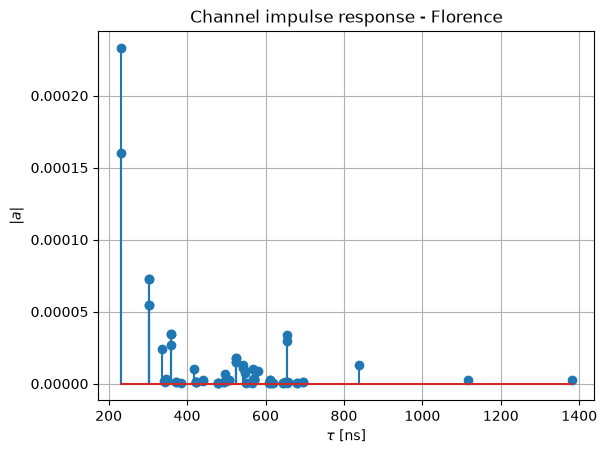

In [112]:
t = tau[0,0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,:,0]
a_max = np.max(a_abs)

# And plot the CIR
plt.figure()
plt.title("Channel impulse response - Florence")
plt.stem(t, a_abs)
plt.grid()
plt.xlabel(r"$\tau$ [ns]")
plt.ylabel(r"$|a|$");

We can obtain the channel frequency response in a similar manner. `paths,cfr` takes the cir (internally) and returns the channel frequency response:
$$
\widehat{h}(f, t) = \sum_{i=0}^{M-1}a_i^\text{b}(t) e^{-j2\pi f \tau_{i}}
$$
Next, it is shown for a bandwidth of 20 MHz at center frequency of ~3 GHz. **Try to set 40MHz later just to see how the system behaves**

Shape of h_freq: (1, 1, 1, 1, 1, 1024)


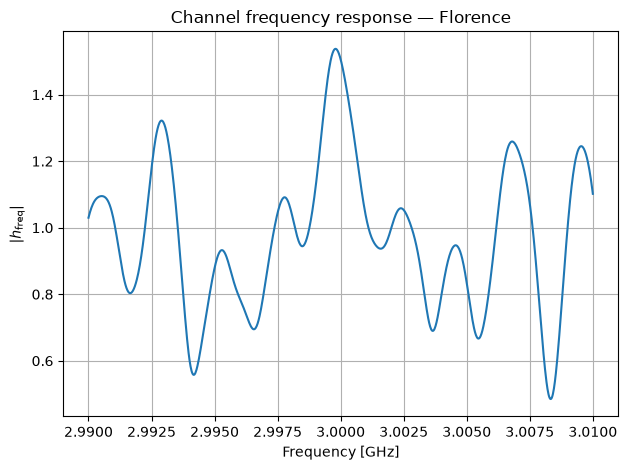

In [165]:
# Frequency sweep: 2.99 to 3.01 GHz
bandwidth = 20e6  # Hz
num_frequencies = 1024
frequencies = np.linspace(-bandwidth/2, bandwidth/2, num_frequencies)
rf_frequencies = carrier_frequency + frequencies

h_freq = paths.cfr(frequencies=frequencies,
                   normalize=True,
                   normalize_delays=False,
                   out_type="numpy")
# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps, num_frequencies]
print("Shape of h_freq:", h_freq.shape)

plt.figure()
plt.plot(rf_frequencies/1e9, np.abs(h_freq[0,0,0,0,0,:]))
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$|h_\mathrm{freq}|$")
plt.title("Channel frequency response — Florence")
plt.grid(True)
plt.tight_layout();


### Delay spread and coherence bandwidth

We select the first transmitter/receiver antenna pair, `(rx, rx_ant, tx, tx_ant) = (0, 0, 0, 0)`, at the time $t=0$. Given $a_i$ and $\tau_i$, $\forall i \in\{0, ..., M-1\}$ of the CIR, we can define: the power-delay profile $P_p=|a_p|^2$, the excess delays $d_i=\tau_i-\min_{0\le k <M}\tau_q$, and the normalized powers $w_i = P_i / \sum_{i=0}^{M-1} P_i$.

From this we can compute the **maximum delay spread** by including every finite, nonzero-power path found by the solver, as:
$$
\sigma_\tau^\max = \max_{0\le i < M} d_i = \max_{i}\tau_i-\min_k\tau_k
$$

Or, we can account for the energy of every path through the **Root Mean Square (RMS) delay spread** which is
$$
\sigma_\tau^\mathrm{RMS}=\sqrt{\sum_{i=0}^{M-1} w_i (d_i - \bar{d})^2},
$$
where $\bar{d}=\sum_{i=0}^{M-1} w_i d_i$.


Delay spread is useful to compute the coherence bandwidth of the channel, measuring how "flat" is the channel for a no-ISI transmission. An old coherence bandwidth formula given in [Tse2002](https://web.stanford.edu/~dntse/papers/book121004.pdf) is
$$
B_{c}^\mathrm{Tse}\approx\frac{1}{2 \sigma^{\max}_\tau},
$$
but other sources uses the RMS metric through
$$
B_{c}\approx\frac{1}{50 \sigma_\tau^\mathrm{RMS}}.
$$

**Try to implement the missing parts of the code in `delay_spread_metrics`**. **Also, try to change the constant of the formula above to see the effect on the metric**.


Florence: link (0, 0, 0, 0), 69 valid paths
  RMS delay spread: 79.510 ns
  Maximum delay spread (all nonzero-power paths): 1149.785 ns
  Approx. Bc: 0.252 MHz
  Approx. Bc for Tse: 0.435 MHz


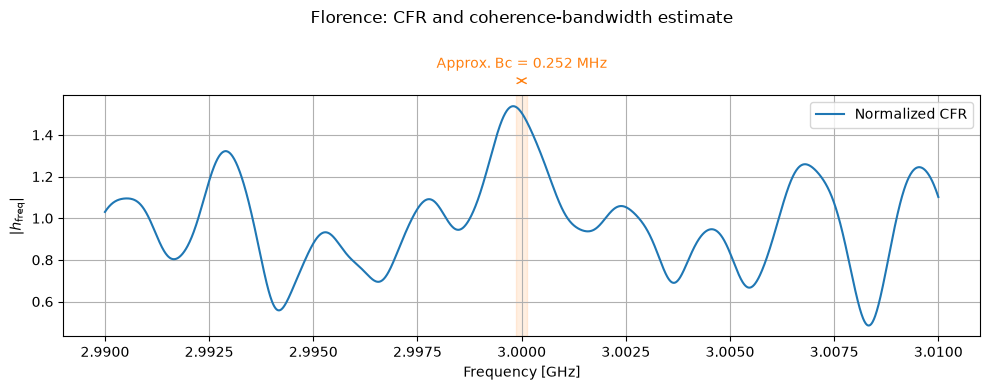

In [166]:
def link_cir(paths_object, link=(0, 0, 0, 0)):
    """Function to extract the finite, nonzero-power paths for one SISO link at t=0 and their absolute delays.
    Do not change this.
    """
    a_all, tau_all = paths_object.cir(normalize_delays=False, 
                                      num_time_steps=1, 
                                      out_type="numpy")
    rx_i, rx_ant_i, tx_i, tx_ant_i = link
    coefficients = np.asarray(a_all[rx_i, rx_ant_i, tx_i, tx_ant_i, :, 0], dtype=np.complex128)
    
    # RT versions/array modes may share path delays across antenna elements.
    if tau_all.ndim == 5:
        delays = np.asarray(tau_all[rx_i, rx_ant_i, tx_i, tx_ant_i, :],
                            dtype=np.float64)
    elif tau_all.ndim == 3:
        delays = np.asarray(tau_all[rx_i, tx_i, :], dtype=np.float64)
    else:
        raise ValueError(f"Unexpected RT delay shape: {tau_all.shape}")
    
    # Check is power is non-negligible
    power = np.abs(coefficients)**2
    valid = (np.isfinite(delays) & (delays >= 0)
             & np.isfinite(coefficients) & (power > 0))
    if not np.any(valid):
        raise ValueError(f"No finite, nonzero-power propagation paths for link {link}.")
    
    # Reorder and output the CIR amplitude and delays
    order = np.argsort(delays[valid])
    return coefficients[valid][order], delays[valid][order]


def delay_spread_metrics(paths_object, link=(0, 0, 0, 0)):
    """Compute delay spread taking a paths object.
    
    Implement the formulas above to obtain the max and rms delay spread.
    """
    # Take CIR removing negligible paths
    coefficients, delays = link_cir(paths_object, link)

    # Compute the formula here (To be commented out)
    power = np.abs(coefficients)**2
    weights = power / power.sum()
    excess_delay = delays - delays.min()
    mean_excess_delay = np.sum(weights * excess_delay)
    rms = float(np.sqrt(np.sum(weights * (excess_delay - mean_excess_delay)**2)))
    return {
        "link": link,
        "num_paths": len(delays),
        "first_delay_s": float(delays.min()),
        "mean_excess_delay_s": float(mean_excess_delay),
        "rms_delay_spread_s": rms,
        "max_delay_spread_s": float(np.ptp(delays)),
        "coherence_bandwidth": 1/(rms*50),        
        "coherence_bandwidth_tse": 1 / float(np.ptp(delays)) / 2,
    }


def print_delay_metrics(metrics, label):
    print(f"{label}: link {metrics['link']}, {metrics['num_paths']} valid paths")
    print(f"  RMS delay spread: {metrics['rms_delay_spread_s']*1e9:.3f} ns")
    print(f"  Maximum delay spread (all nonzero-power paths): "
          f"{metrics['max_delay_spread_s']*1e9:.3f} ns")
    print(f"  Approx. Bc: {metrics['coherence_bandwidth']/1e6:.3f} MHz")    
    print(f"  Approx. Bc for Tse: {metrics['coherence_bandwidth_tse']/1e6:.3f} MHz")    


def plot_cfr_with_coherence(paths_object, metrics, center_frequency, 
                            label, sweep_bandwidth=20e6):
    """Show the Bc estimate as an actual-width interval above the CFR."""
    bc = metrics["coherence_bandwidth"]
    # Widen the display if needed so the entire coherence-bandwidth bracket fits.
    span = max(sweep_bandwidth, 1.4*bc) if np.isfinite(bc) else sweep_bandwidth
    offsets = np.linspace(-span/2, span/2, 2048)
    h = paths_object.cfr(frequencies=offsets, 
                         normalize=True,
                         normalize_delays=False, 
                         out_type="numpy")
    rx_i, rx_ant_i, tx_i, tx_ant_i = metrics["link"]
    magnitude = np.abs(h[rx_i, rx_ant_i, tx_i, tx_ant_i, 0, :])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot((center_frequency + offsets)/1e9, magnitude, label="Normalized CFR")
    if np.isfinite(bc):
        left, right = (center_frequency + np.array([-bc/2, bc/2]))/1e9
        ax.axvspan(left, right, alpha=0.12, color="tab:orange")
        # x in GHz, y in axes coordinates: keep the bracket above the curve.
        transform = ax.get_xaxis_transform()
        ax.annotate("", xy=(left, 1.06), xytext=(right, 1.06),
                    xycoords=transform, textcoords=transform,
                    arrowprops=dict(arrowstyle="<->", color="tab:orange"),
                    annotation_clip=False)
        ax.text((left+right)/2, 1.10, f"Approx. Bc = {bc/1e6:.3f} MHz", 
                transform=transform, ha="center", va="bottom", color="tab:orange")
    else:
        ax.text(0.5, 1.08, "Zero RMS delay spread: estimated Bc is infinite",
                transform=ax.transAxes, ha="center")
    ax.set(xlabel="Frequency [GHz]", ylabel=r"$|h_\mathrm{freq}|$",
           title=f"{label}: CFR and coherence-bandwidth estimate")
    ax.set_title(ax.get_title(), pad=52)
    ax.grid(True)
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()
    return fig, ax


florence_metrics = delay_spread_metrics(paths_florence)
print_delay_metrics(florence_metrics, "Florence")
_ = plot_cfr_with_coherence(paths, florence_metrics, carrier_frequency, "Florence",
                            sweep_bandwidth=bandwidth)


### CFR under mobility

Our aim here is to show the time variability of the channel under user mobility (whenever present).

First use the original `paths`, computed with stationary devices and objects. **Run the following to see the plot in two dimensions.**

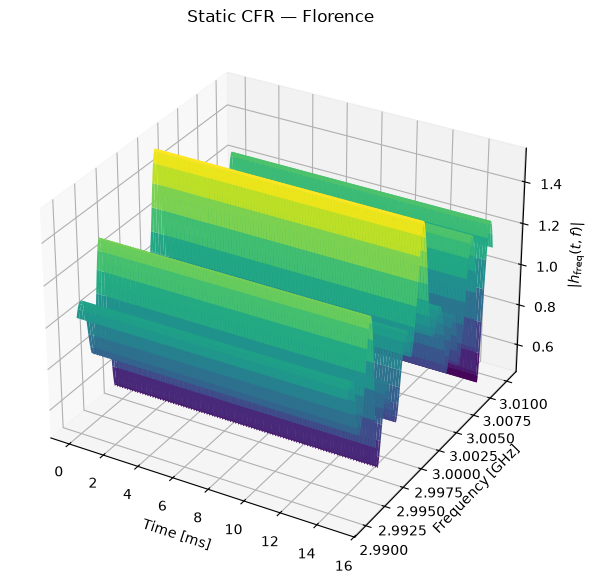

In [167]:
# Plot function for time, frequency visualization
def plot_cfr_surface(h, title):
    fig = plt.figure(figsize=(10, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(time_grid, frequency_grid, np.abs(h[0,0,0,0,:,:]),
                    cmap="viridis", rcount=100, ccount=128)
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Frequency [GHz]")
    ax.set_zlabel(r"$|h_\mathrm{freq}(t,f)|$")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


# Static reference: use the original paths without recomputing them.
num_time_steps = 300
sampling_frequency = 20e3  # Hz
h_freq_static = paths.cfr(frequencies=frequencies,
                          sampling_frequency=sampling_frequency, 
                          num_time_steps=num_time_steps,
                          normalize=True, 
                          normalize_delays=False, 
                          out_type="numpy")

time_ms = np.arange(num_time_steps)/sampling_frequency*1e3
time_grid, frequency_grid = np.meshgrid(time_ms, rf_frequencies/1e9, indexing="ij")

plot_cfr_surface(h_freq_static, "Static CFR — Florence")


Every radio device and scene object has a velocity vector, used to compute path-specific Doppler shifts. Set the transmitter velocity to a value in m/s and recompute `paths_mob` using the same solver settings as the static case. The CFR then evolves according to these Doppler shifts, with geometry held at the traced snapshot. This is just an approximation, as we will se in a minute...

Shape of channel is: (1, 1, 1, 1, 300, 1024)


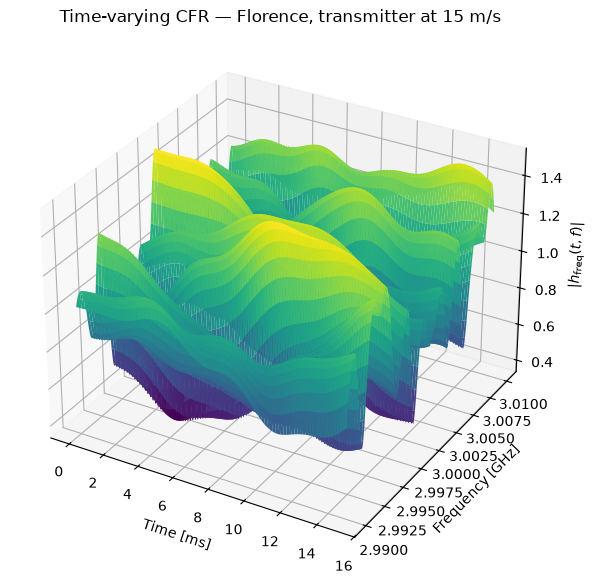

In [168]:
speed_mag = 15    # To be left empty
speed_vec = speed_mag * -np.array(rx.orientation)    # The rx is looking the tx and it is moving backwards

scene_florence.get("tx").velocity = speed
try:
    paths_mob = p_solver(scene=scene_florence,
                         max_depth=5, 
                         los=True, 
                         specular_reflection=True,
                         diffuse_reflection=False, 
                         refraction=True,
                         synthetic_array=False, 
                         seed=41)
finally:
    # Restore the scene for repeatable static experiments.
    scene_florence.get("tx").velocity = [0, 0, 0]

h_freq_mob = paths_mob.cfr(frequencies=frequencies,
                           sampling_frequency=sampling_frequency, 
                           num_time_steps=num_time_steps,
                           normalize=True, 
                           normalize_delays=False, 
                           out_type="numpy")

# The shape is: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps, num_subcarriers]
print(f"Shape of channel is: {h_freq_mob.shape}")

plot_cfr_surface(h_freq_mob, f"Time-varying CFR — Florence, transmitter at {speed_mag} m/s")

Let us just check a single frequency now, just to better visualize what is going on to the amplitude and phase of the channel on a narrow band. **Try to select another frequency, first close to the central frequency (like +1 or -1) and then set freq_idx = 0**, what difference do you see?

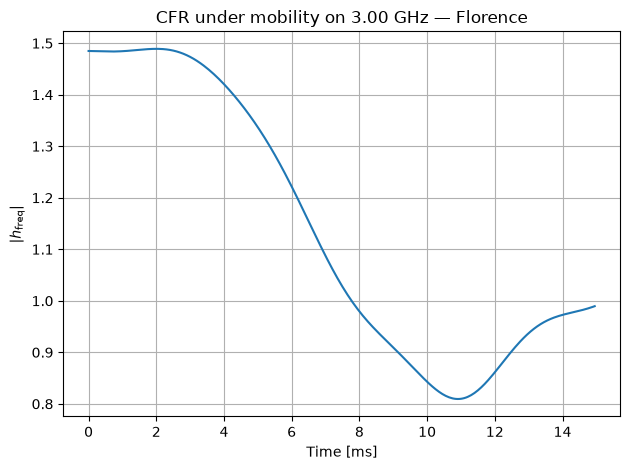

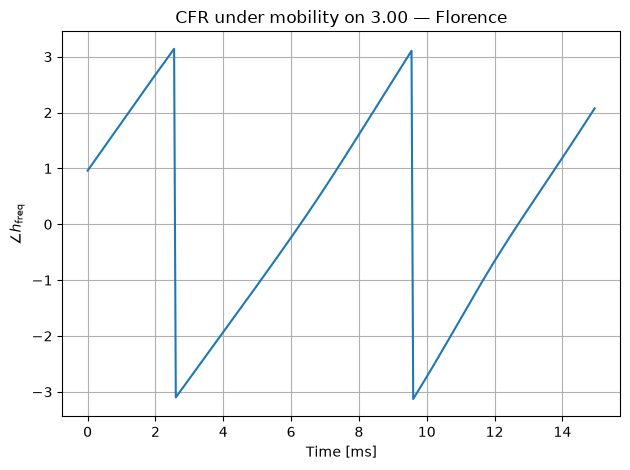

In [169]:
freq_idx = num_frequencies // 2 + 0
h_visual = h_freq_mob[0, 0, 0, 0, :, freq_idx]

# Printing the value in GHz of the central_freq
freq_selected = rf_frequencies[freq_idx]/1e9

plt.figure()
plt.plot(time_ms, np.abs(h_visual))
plt.xlabel("Time [ms]")
plt.ylabel(r"$|h_\mathrm{freq}|$")
plt.title(f"CFR under mobility on {freq_selected:.2f} GHz — Florence")
plt.grid(True)
plt.tight_layout();

plt.figure()
plt.plot(time_ms, np.angle(h_visual))
plt.xlabel("Time [ms]")
plt.ylabel(r"$\angle h_\mathrm{freq}$")
plt.title(f"CFR under mobility on {freq_selected:.2f} — Florence")
plt.grid(True)
plt.tight_layout();

### Doppler spread and coherence time
Another useful metric of a channel is the Doppler spread, which can be evaluated as TOBEDONE

and represent WHAT?

Considering the setting above, **implement the formula for the coherence time, and run the block** to compare it with the CFR response.

In [ ]:
# Doppler spread TBD

### Testing the Doppler approximation
Take it from the mobility tutorial

## Transmission simulations

We now send **one uncoded block of QAM symbols through the static ray-traced channel in the time domain**, using [Sionna PHY 2.2.0](https://nvlabs.github.io/sionna/phy/). 

`BinarySource` → `Mapper` → `cir_to_time_channel` / `ApplyTimeChannel` (multipath convolution + AWGN) → single-tap gain correction → hard `Demapper`.

Assumptions for this small teaching example:

- One transmit and one receive antenna: the same link `(0, 0, 0, 0)` used for the statistics. The CIR is frozen at $t=0$; mobility is not simulated here.
- Ideal sinc pulse shaping and matched receive filtering, as assumed by [`cir_to_time_channel`](https://nvlabs.github.io/sionna/phy/api/channel/wireless/sionna.phy.channel.cir_to_time_channel.html). The symbol/sample rate is $B$ symbols/s, with occupied complex-baseband band $[-B/2,B/2]$.
- Perfect timing and knowledge of the strongest sampled channel tap. Only its complex gain is corrected; all the other taps still cause **intersymbol interference (ISI)**. No coding, OFDM, cyclic prefix, channel estimation, or multi-tap equalizer is used.
- We subtract the first path delay **only inside the synchronized transmission model**. This removes bulk propagation latency, preserves the delay spread and ISI, and leaves the absolute-delay CIR/CFR plots above unchanged.
- The discrete channel is normalized to unit tap energy for each bandwidth. QAM has unit average symbol energy. `snr_db` specifies nominal $E_s/N_0$ in dB after this normalization, so the **linear variance per complex receive sample** is $N_0=10^{-\mathrm{snr\_db}/10}$. This is not dBm or a noise spectral density. Keeping SNR fixed isolates channel dispersion rather than path loss or the change of integrated thermal noise with bandwidth.

`__init__` creates all the Sionna processing blocks. A fixed tap budget lets the same instance test different bandwidths; `__call__` checks that the sampled excess delays fit before it runs. The sinc response is truncated with six samples of margin around the physical delays, with additional unused taps zeroed. The number of symbols and the maximum tap budget can be changed in the constructor.


In [84]:
import torch
from sionna.phy import config as phy_config
from sionna.phy.mapping import BinarySource, Mapper, Demapper
from sionna.phy.channel import cir_to_time_channel, ApplyTimeChannel


class QAMTransmission:
    """One static SISO QAM block with a single-tap receiver, on CPU."""

    def __init__(self, num_symbols=1024, num_bits_per_symbol=4,
                 max_excess_delay_samples=512, seed=42, link=(0, 0, 0, 0)):
        if num_symbols <= 0 or int(num_symbols) != num_symbols:
            raise ValueError("num_symbols must be a positive integer.")
        if (num_bits_per_symbol <= 0 or num_bits_per_symbol % 2
                or int(num_bits_per_symbol) != num_bits_per_symbol):
            raise ValueError("QAM needs a positive even number of bits per symbol.")
        if (max_excess_delay_samples < 0
                or int(max_excess_delay_samples) != max_excess_delay_samples):
            raise ValueError("max_excess_delay_samples must be a nonnegative integer.")
        self.num_symbols = int(num_symbols)
        self.num_bits_per_symbol = int(num_bits_per_symbol)
        self.seed = seed
        self.link = link
        self.l_min = -6
        self.l_max = int(max_excess_delay_samples) + 6
        self.l_tot = self.l_max - self.l_min + 1
        # All processing blocks are instantiated once, not inside __call__.
        self.binary_source = BinarySource(device="cpu")
        self.mapper = Mapper("qam", self.num_bits_per_symbol, device="cpu")
        self.channel = ApplyTimeChannel(self.num_symbols, self.l_tot, device="cpu")
        self.demapper = Demapper("app", constellation=self.mapper.constellation,
                                hard_out=True, device="cpu")

    def __call__(self, bandwidth, snr_db, paths_object):
        bandwidth, snr_db = float(bandwidth), float(snr_db)
        if not np.isfinite(bandwidth) or bandwidth <= 0:
            raise ValueError("bandwidth must be finite and strictly positive, in Hz.")
        if not np.isfinite(snr_db):
            raise ValueError("snr_db must be finite (dB units).")
        coefficients, delays = link_cir(paths_object, self.link)
        delays = delays - delays.min()  # Perfect synchronization to first arrival.
        required_l_max = int(np.ceil(bandwidth*delays.max())) + 6
        if required_l_max > self.l_max:
            raise ValueError(
                f"This bandwidth needs l_max >= {required_l_max}; increase "
                "max_excess_delay_samples when constructing QAMTransmission.")
        
        # Convert snr to noise value        
        noise = torch.tensor(1 / float(sionna.phy.utils.db_to_lin(snr_db)), dtype=torch.float32)        
            

        # RT has no batch dimension; explicitly build a one-link PHY CIR.
        # a: [batch, rx, rx_ant, tx, tx_ant, paths, time]; tau: [batch, rx, tx, paths]
        # Rescale coefficients before float32 conversion; normalization below
        # removes this common scale and avoids underflow for very weak links.
        coefficients = coefficients / np.sqrt(np.sum(np.abs(coefficients)**2))
        a_phy = torch.as_tensor(coefficients, dtype=torch.complex64).reshape(1, 1, 1, 1, 1, -1, 1)
        tau_phy = torch.as_tensor(delays, dtype=torch.float32).reshape(1, 1, 1, -1)
        h = cir_to_time_channel(bandwidth, a_phy, tau_phy, l_min=self.l_min, l_max=self.l_max, normalize=False)
        
        # Six-sample right-hand sinc margin, followed by unused zero taps.
        active_taps = required_l_max - self.l_min + 1
        h[..., active_taps:] = 0
        tap_energy = h.abs().square().sum()
        if not torch.isfinite(tap_energy) or tap_energy <= 0:
            raise ValueError("The sampled channel has zero/nonfinite energy.")
        h = h / torch.sqrt(tap_energy)
        taps_siso = h.reshape(-1)
        peak_index = int(torch.argmax(taps_siso.abs().square()).item())
        gain = taps_siso[peak_index]

        # Reuse the same bits/noise seed for a fair comparison of bandwidths.
        phy_config.seed = self.seed
        
        # Generate random bits
        bits = self.binary_source([1, 1, 1, self.num_symbols*self.num_bits_per_symbol])
        # Map bits to QAM symbols
        symbols = self.mapper(bits)
        
        # ApplyTimeChannel expects a channel sample for every output sample.
        h_time = h.expand(1, 1, 1, 1, 1, self.num_symbols + self.l_tot - 1, self.l_tot)
        
        # Apply channel over transmitted bit
        received = self.channel(symbols, h_time, noise)
        
        # Array index 0 represents physical lag l_min. Align to the peak tap.
        aligned = received[..., peak_index:peak_index + self.num_symbols]
        equalized = aligned / gain
        effective_noise = noise / gain.abs().square()
        
        # The floor only keeps the demapper well-defined in a noiseless test.
        bits_hat = self.demapper(equalized, effective_noise.clamp_min(1e-12))
        b = bits.detach().cpu().numpy().reshape(-1).astype(np.int32)
        b_hat = bits_hat.detach().cpu().numpy().reshape(-1).astype(np.int32)
        errors = int(np.count_nonzero(b != b_hat))
        isi_energy = float((taps_siso.abs().square().sum() - gain.abs().square()).item())
        return {
            "bandwidth_hz": bandwidth, "snr_db": snr_db, "noise_power": float(noise.item()),
            "bits": b, "bits_hat": b_hat,
            "symbols": symbols.detach().cpu().numpy().reshape(-1),
            "received_symbols": equalized.detach().cpu().numpy().reshape(-1),
            "received_samples": received.detach().cpu().numpy().reshape(-1),
            "taps": taps_siso.detach().cpu().numpy(),
            "tap_lags": np.arange(self.l_min, self.l_max + 1),
            "peak_lag": self.l_min + peak_index,
            "isi_to_main_power": isi_energy / float(gain.abs().square().item()),
            "num_errors": errors, "ber": errors / len(b),
        }


### Compare a narrow band with a band wider than the coherence estimate

The same class instance sends the same **4096-bit, 16-QAM block** through the same Florence paths with $B=0.1B_c$ and $B=10B_c$. The `snr_db = X` variable here correspond with and $E_s/N_0$ of X dB before accounting for ISI and peak-tap gain.

Each plot shows the **first 100 transmitted and hard-decided received bits**, with errors marked in red. The BER printed in the title is computed over the entire block. Bit index is used so the streams can be compared directly; the simulated block duration is also printed. These are two single-block demonstrations, not Monte Carlo BER estimates. A wide band can still work well for a dominant-path channel: exceeding the heuristic $B_c$ does not guarantee bit errors.


In [170]:
# Simulate each bandwidth once; reuse these results in both plots below.
transmission = QAMTransmission(num_symbols=1024, num_bits_per_symbol=4)
coherence_bandwidth = florence_metrics["coherence_bandwidth"]
snr_db =  30  # SNR after channel normalization
transmission_results = {}

if not np.isfinite(coherence_bandwidth) or coherence_bandwidth <= 0:
    print("No finite positive coherence-bandwidth estimate: the two B/Bc cases "
          "are undefined. Choose a multipath link with nonzero RMS delay spread.")
else:
    cases = [("a) Narrow band", 0.1*coherence_bandwidth),
             ("b) Wide band", 10*coherence_bandwidth)]
    for label, transmission_bandwidth in cases:
        transmission_results[label] = transmission(transmission_bandwidth, snr_db, paths)


### Received symbols on the constellation plane

Before inspecting the bit decisions, compare all 1024 received symbols with the ideal normalized 16-QAM constellation. The points shown are the samples **after timing alignment and single-tap complex-gain correction, before hard demapping**. Both panels use the same axis limits and equal I/Q scaling. A wider cloud shows residual noise and intersymbol interference; these are the same realizations used in the bit-stream plots below.

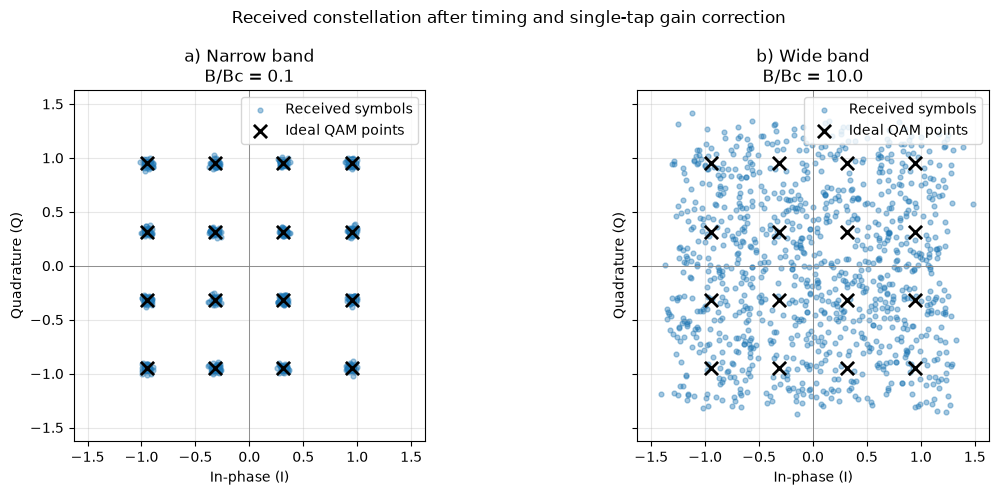

In [172]:
# Get the exact normalized reference constellation used by the Sionna mapper.
ideal_points = transmission.mapper.constellation().detach().cpu().numpy().reshape(-1)
all_points = np.concatenate([ideal_points] + [result["received_symbols"] for result in transmission_results.values()])
axis_limit = 1.1 * max(np.max(np.abs(all_points.real)),
                       np.max(np.abs(all_points.imag)), 1.0)


# Generate two plots for the I/Q results of the different bandwidths
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (label, result) in zip(axes, transmission_results.items()):
    # Take received symbols from items
    received_symbols = result["received_symbols"]

    # Scatter plot of received and ideal points
    ax.scatter(received_symbols.real, received_symbols.imag,
               s=12, alpha=0.4, color="tab:blue", label="Received symbols")
    ax.scatter(ideal_points.real, ideal_points.imag, s=90, marker="x",
               linewidths=2, color="black", label="Ideal QAM points", zorder=3)
    
    # Add I/Q lines
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    
    # Set limits, labels, and title
    ax.set(xlim=(-axis_limit, axis_limit), ylim=(-axis_limit, axis_limit),
           xlabel="In-phase (I)", ylabel="Quadrature (Q)",
           title=f"{label}\nB/Bc = {result['bandwidth_hz']/coherence_bandwidth:.1f}")
    
    # Set decorators
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
fig.suptitle("Received constellation after timing and single-tap gain correction")
fig.tight_layout()
plt.show()


### Transmission results: transmitted and received bits

These plots reuse the same simulated blocks shown in the constellation plots above.

a) Narrow band: B = 0.025 MHz, B/Bc = 0.1, duration = 40709.26 us
  0/4096 bit errors; BER = 0; ISI/main-tap power = 1.514e-05
b) Wide band: B = 2.515 MHz, B/Bc = 10.0, duration = 407.09 us
  187/4096 bit errors; BER = 0.04565; ISI/main-tap power = 0.08551


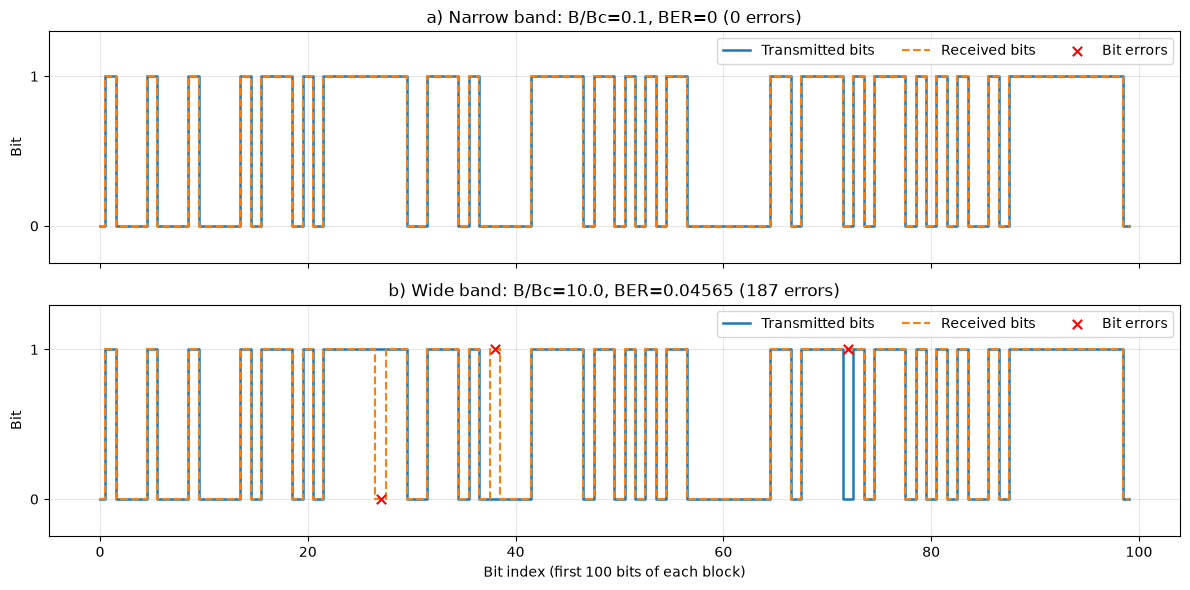

In [173]:
# Generate the figure
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, (label, result) in zip(axes, transmission_results.items()):
    transmission_bandwidth = result["bandwidth_hz"]
    print(f"{label}: B = {transmission_bandwidth/1e6:.3f} MHz, "
          f"B/Bc = {transmission_bandwidth/coherence_bandwidth:.1f}, "
          f"duration = {transmission.num_symbols/transmission_bandwidth*1e6:.2f} us")
    print(f"  {result['num_errors']}/{len(result['bits'])} bit errors; "
          f"BER = {result['ber']:.4g}; "
          f"ISI/main-tap power = {result['isi_to_main_power']:.4g}")
    # Take the first 100 bits
    count = min(100, len(result["bits"]))
    indices = np.arange(count)
    sent = result["bits"][:count]
    detected = result["bits_hat"][:count]
    # Check wrong bits
    wrong = sent != detected
    
    # Draw bits and errors
    ax.step(indices, sent, where="mid", label="Transmitted bits", linewidth=1.8)
    ax.step(indices, detected, where="mid", label="Received bits", linestyle="--")
    ax.scatter(indices[wrong], detected[wrong], color="red", marker="x",
               s=45, label="Bit errors", zorder=3)
    ax.set(yticks=[0, 1], ylim=(-0.25, 1.3), ylabel="Bit",
           title=f"{label}: B/Bc={transmission_bandwidth/coherence_bandwidth:.1f}, "
                 f"BER={result['ber']:.4g} ({result['num_errors']} errors)")
    # Add decorators
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", ncol=3)

# Set commont labels and show the plot
axes[-1].set_xlabel("Bit index (first 100 bits of each block)")
fig.tight_layout()
plt.show()


### BER versus SNR: narrow and wide bands

Sweep `snr_db` from **−6 to 30 dB**, inclusive, in 3 dB steps. Use the two bandwidths from the preceding experiment and the same frozen Florence channel and single-tap receiver. Here SNR means nominal $E_s/N_0$ (not $E_b/N_0$), with $N_0=10^{-\mathrm{snr\_db}/10}$ after unit-energy channel normalization.

At each SNR, simulate 20 independent 4096-bit blocks (81,920 bits per curve point). Each block gets a new seed; the two bandwidths share the bits and underlying noise realization for that block. Errors and bit counts are accumulated before computing BER. These curves measure this fixed link, not an average over UE positions.

The first cell runs the sweep; the second plots the results. Increase `num_blocks_per_snr` to resolve lower BERs. If no errors occur, the plot shows a downward triangle at the one-sided 95% binomial upper bound (an independent-bit-error approximation) $1-0.05^{1/N}$, rather than inventing a nonzero BER for the logarithmic axis. Residual ISI can produce a high-SNR error floor in the wider band.


In [174]:
# Set snr values to sweep through
snr_db_values = np.arange(-6, 31, 3, dtype=float)
num_blocks_per_snr = 20
ber_seed = 42
ber_sweep = {}

# 
ber_bandwidths = {label: result["bandwidth_hz"]
                  for label, result in transmission_results.items()}
# Size the fixed channel-tap budget for the widest band, instead of allocating
# the larger default budget on every Monte Carlo call.
_, sweep_delays = link_cir(paths, transmission.link)
max_delay_samples = int(np.ceil(max(ber_bandwidths.values()) * np.ptp(sweep_delays)))
ber_transmission = QAMTransmission(num_symbols=1024, 
                                   num_bits_per_symbol=transmission.num_bits_per_symbol,
                                   max_excess_delay_samples=max_delay_samples, 
                                   link=transmission.link)

# Generate the container for the results
for label, band in ber_bandwidths.items():
    ber_sweep[label] = {
        "bandwidth_hz": band,
        "errors": np.zeros(len(snr_db_values), dtype=np.int64),
        "num_bits": np.zeros(len(snr_db_values), dtype=np.int64),
    }
    
# Sweep through all the snr values
for snr_index, snr_value in enumerate(snr_db_values):
    for block_index in range(num_blocks_per_snr):
        # __call__ resets the PHY RNG; use a new seed for every block/SNR.
        # Keep this seed identical across the two bandwidths.
        ber_transmission.seed = ber_seed + snr_index*num_blocks_per_snr + block_index
        
        # Tests for the two bandwidths
        for label, band in ber_bandwidths.items():
            block_result = ber_transmission(band, float(snr_value), paths)
            ber_sweep[label]["errors"][snr_index] += block_result["num_errors"]
            ber_sweep[label]["num_bits"][snr_index] += len(block_result["bits"])
    # Print metrics
    print(f"SNR = {snr_value:5.1f} dB: " + "; ".join(
        f"{label}: {data['errors'][snr_index]}/{data['num_bits'][snr_index]} errors"
        for label, data in ber_sweep.items()))

# Compute ber
for data in ber_sweep.values():
    data["ber"] = data["errors"] / data["num_bits"]
    data["zero_error_upper_95"] = -np.expm1(np.log(0.05)/data["num_bits"])


SNR =  -6.0 dB: a) Narrow band: 32232/81920 errors; b) Wide band: 32551/81920 errors
SNR =  -3.0 dB: a) Narrow band: 28137/81920 errors; b) Wide band: 28923/81920 errors
SNR =   0.0 dB: a) Narrow band: 23255/81920 errors; b) Wide band: 24580/81920 errors
SNR =   3.0 dB: a) Narrow band: 17292/81920 errors; b) Wide band: 19285/81920 errors
SNR =   6.0 dB: a) Narrow band: 11451/81920 errors; b) Wide band: 14434/81920 errors
SNR =   9.0 dB: a) Narrow band: 6421/81920 errors; b) Wide band: 10828/81920 errors
SNR =  12.0 dB: a) Narrow band: 2269/81920 errors; b) Wide band: 8167/81920 errors
SNR =  15.0 dB: a) Narrow band: 354/81920 errors; b) Wide band: 6319/81920 errors
SNR =  18.0 dB: a) Narrow band: 10/81920 errors; b) Wide band: 5273/81920 errors
SNR =  21.0 dB: a) Narrow band: 0/81920 errors; b) Wide band: 4511/81920 errors
SNR =  24.0 dB: a) Narrow band: 0/81920 errors; b) Wide band: 4026/81920 errors
SNR =  27.0 dB: a) Narrow band: 0/81920 errors; b) Wide band: 3763/81920 errors
SNR =

The following plots the results for both bandwidths.

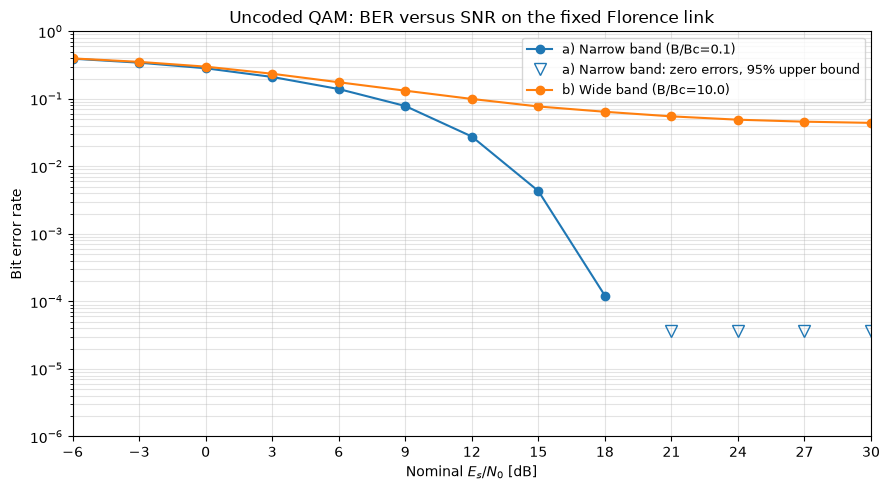

In [175]:
# Create the plot
fig, ax = plt.subplots(figsize=(9, 5))

# Cycle through the different results
for color_index, (label, data) in enumerate(ber_sweep.items()):
    color = f"C{color_index}"
    positive = data["errors"] > 0
    measured_ber = np.where(positive, data["ber"], np.nan)
    ratio = data["bandwidth_hz"] / coherence_bandwidth
    ax.semilogy(snr_db_values, measured_ber, "o-", color=color,
                label=f"{label} (B/Bc={ratio:.1f})")
    if np.any(~positive):
        ax.semilogy(snr_db_values[~positive],
                    data["zero_error_upper_95"][~positive], "v",
                    color=color, linestyle="none", markerfacecolor="none",
                    markersize=8, label=f"{label}: zero errors, 95% upper bound")
ax.set(xlabel=r"Nominal $E_s/N_0$ [dB]", ylabel="Bit error rate",
       title="Uncoded QAM: BER versus SNR on the fixed Florence link",
       xlim=(snr_db_values[0], snr_db_values[-1]), ylim=(1e-6, 1))
ax.set_xticks(snr_db_values)
ax.grid(True, which="both", alpha=0.35)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


## Statistical channel model

Create a spatial ensemble of **N UEs**: keep the original receiver and sample **N - 1 additional UEs** in outdoor positions at $z=1.5$ m. A separate Florence scene uses the current transmitter position, orientation, frequency and antenna arrays.

Sample $(x,y)$ uniformly in a **200 m × 200 m region centered on the original UE**, clipped to the scene's bounding rectangle with a 1 m boundary margin (`stat_region_center` and `stat_region_half_width` are adjustable), rejecting positions whose first top-down intersection is not the Florence ground plane at $z=0$. This excludes rooftops and locations inside buildings for this flat-ground scene. The sampler is independent of channel strength: UEs with no computed path are retained and reported as outages. The fixed transmitter beam direction is preserved rather than steered separately for each UE. The geometric sampling seed and deterministic path-solver seed are fixed for reproducibility.

The next cell traces all links using `PathSolver`, in batches of five UEs with 100,000 ray samples per source to limit memory use on lab PCs. The raw CIRs for each group are saved in `stat_batch_cirs`, and all CFRs are concatenated in UE order into `h_freq_stat`. The histogram cell evaluates their CFR over 20 MHz around the carrier, then takes **one complex CFR sample per UE at the exact carrier frequency**, using the first antenna pair. Absolute delays and phases are retained. A common RMS normalization over the nonzero samples only rescales the magnitude axis.

Compare the magnitude histogram with a **Gaussian fitted to its sample mean and standard deviation**, and the phase with $\mathcal U(-\pi,\pi)$, whose PDF is $1/(2\pi)$. A Gaussian is a comparison curve, **not an assumed amplitude law**: for a circular complex Gaussian channel, its real/imaginary components are Gaussian and its magnitude is Rayleigh. A Rayleigh reference is therefore also overlaid. LoS links, different UE distances, shadowing and the finite sample of 100 links can all produce deviations. These plots are exploratory comparisons, not proof that the spatial ensemble follows a particular model. See [Tse and Viswanath, Chapter 2](https://web.stanford.edu/~dntse/papers/main.pdf).


In [93]:
# Just to have a progress bar :)
from tqdm.notebook import trange, tqdm

# Independent scene: rerunning this cell does not accumulate receivers.
scene_stat = load_scene(sionna.rt.scene.florence, merge_shapes=True)
scene_stat.frequency = scene_florence.frequency
scene_stat.tx_array = scene_florence.tx_array
scene_stat.rx_array = scene_florence.rx_array
original_tx = scene_florence.get("tx")
original_rx = scene_florence.get("rx")
scene_stat.add(Transmitter(name="tx", position=original_tx.position.numpy().reshape(3),
                           orientation=original_tx.orientation.numpy().reshape(3),
                           display_radius=2))
scene_stat.add(Receiver(name="rx", position=original_rx.position.numpy().reshape(3),
                        orientation=original_rx.orientation.numpy().reshape(3),
                        display_radius=1))


def sample_outdoor_ue_positions(scene, center_xy, half_width=100.0,
                                count=99, height=1.5, seed=20261028):
    """Uniform rejection sampling on the flat Florence ground footprint."""
    rng = np.random.default_rng(seed)
    bbox = scene.mi_scene.bbox()
    lower = bbox.min.numpy().reshape(3)
    upper = bbox.max.numpy().reshape(3)
    # Configurable local region, clipped to the scene footprint.
    center_xy = np.asarray(center_xy, dtype=float)
    low_xy = np.maximum(lower[:2] + 1.0, center_xy - half_width)
    high_xy = np.minimum(upper[:2] - 1.0, center_xy + half_width)
    if np.any(high_xy <= low_xy):
        raise ValueError("The sampling region does not overlap the scene footprint.")
    ray_height = float(upper[2] + 10.0)
    accepted = []
    for _ in range(100):
        xy = rng.uniform(low_xy, high_xy, size=(512, 2))
        ray = mi.Ray3f(
            o=mi.Point3f(mi.Float(xy[:, 0]), mi.Float(xy[:, 1]), ray_height),
            d=mi.Vector3f(0, 0, -1))
        hit = scene.mi_scene.ray_intersect(ray)
        ground = (hit.is_valid().numpy()
                  & np.isfinite(hit.p.z.numpy())
                  & (np.abs(hit.p.z.numpy()) < 0.05))
        for x, y in xy[ground]:
            accepted.append([x, y, height])
            if len(accepted) == count:
                return np.asarray(accepted)
    raise RuntimeError("Could not sample enough outdoor UEs; check the sampling region.")

num_ues = 10000
stat_region_half_width = 100.0  # 200 m x 200 m region around the original UE
stat_region_center = original_rx.position.numpy().reshape(3)[:2]

# Generate new_ues
new_ue_positions = sample_outdoor_ue_positions(
    scene_stat, center_xy=stat_region_center, half_width=stat_region_half_width,
    count=num_ues-1, height=1.5)

ue_names = ["rx"] + [f"ue_{index:03d}" for index in range(1, num_ues)]

# Add receiver in the scene
for name, position in zip(ue_names[1:], new_ue_positions):
    scene_stat.add(Receiver(name=name, position=position, display_radius=1))
ue_positions = np.vstack([original_rx.position.numpy().reshape(3), new_ue_positions])

# Trace in small batches to bound memory use on lab PCs. Receiver devices
# are probes, so evaluating them in separate groups does not change the geometry.
stat_batch_size = 5
stat_samples_per_src = 1000000  # Increase for a path-discovery convergence study.
stat_frequency_offsets = np.linspace(-bandwidth/2, bandwidth/2, 257)
stat_solver = PathSolver(deterministic=True)
stat_receivers = list(scene_stat.receivers.values())
stat_batch_cirs = []
stat_cfr_parts = []

# Remove any already set receiver to avoid recomputing the trace
for receiver in stat_receivers:
    scene_stat.remove(receiver.name)

# Block inserting stat_batch_size receiver every loop and computing the paths
iterations = range(0, len(stat_receivers), stat_batch_size)

try:
    for first in tqdm(iterations):
        batch_receivers = stat_receivers[first:first + stat_batch_size]
        for receiver in batch_receivers:
            scene_stat.add(receiver)
        #print(f"Tracing UEs {first+1}-{first+len(batch_receivers)} of {len(stat_receivers)}...", flush=True)
        batch_paths = stat_solver(scene=scene_stat, max_depth=5, los=True,
            specular_reflection=True, diffuse_reflection=False, refraction=False,
            synthetic_array=False, samples_per_src=stat_samples_per_src,
            max_num_paths_per_src=stat_samples_per_src, seed=41)
        batch_a, batch_tau = batch_paths.cir(normalize_delays=False, out_type="numpy")
        stat_batch_cirs.append({"ue_names": [r.name for r in batch_receivers],
                               "a": batch_a, "tau": batch_tau})
        stat_cfr_parts.append(batch_paths.cfr(
            frequencies=stat_frequency_offsets,
            normalize=False, 
            normalize_delays=False, 
            out_type="numpy")
        )
        # Remove the receiver already traced and destroy the path to free RAM
        for receiver in batch_receivers:
            scene_stat.remove(receiver.name)
        del batch_paths
finally:
    # Leave all num_ue UEs in the statistical scene, even if a batch raises an error.
    for name in list(scene_stat.receivers):
        scene_stat.remove(name)
    for receiver in stat_receivers:
        scene_stat.add(receiver)
h_freq_stat = np.concatenate(stat_cfr_parts, axis=0)
print(f"CFRs computed for all {num_ues} UEs; raw CIRs are in stat_batch_cirs.", flush=True)

  0%|          | 0/2000 [00:00<?, ?it/s]

CFRs computed for all 10000 UEs; raw CIRs are in stat_batch_cirs.


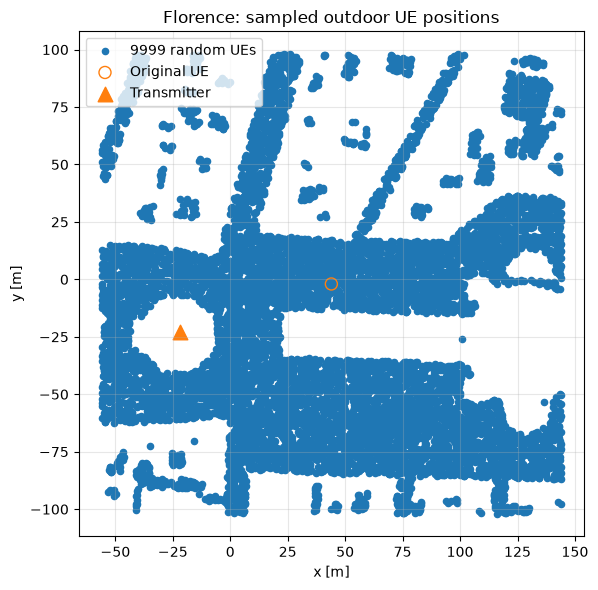

In [83]:
# Visualize the UE position with a scatter plot
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(new_ue_positions[:, 0], new_ue_positions[:, 1], s=20, label=f"{num_ues-1} random UEs")
ax.scatter(ue_positions[0, 0], ue_positions[0, 1], s=75, marker="o",
           facecolors="none", edgecolors="C1", label="Original UE")
tx_position_stat = original_tx.position.numpy().reshape(3)
ax.scatter(tx_position_stat[0], tx_position_stat[1], s=110, marker="^", label="Transmitter")
ax.set(xlabel="x [m]", ylabel="y [m]", title="Florence: sampled outdoor UE positions")
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [50]:
if not no_preview:
    scene_stat.preview()

In [41]:
h_stat_sweep.shape

(10000, 257)

Carrier 3.000 GHz: 8846/10000 nonzero finite links, 1154 zero computed channels, 0 nonfinite samples.


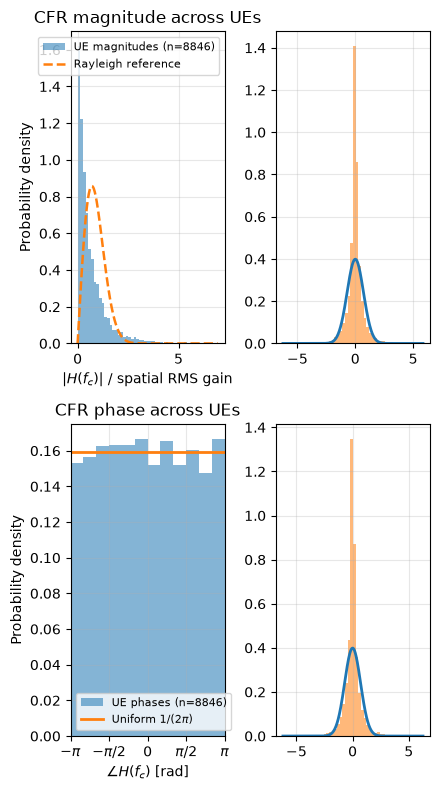

Magnitude Gaussian fit: mean=0.004-0.000j, std=1.000; Rayleigh scale=0.707.


In [92]:
# The odd 257-bin frequency grid includes the exact carrier (offset 0 Hz).
# h_freq_stat contains the raw CFRs concatenated in UE insertion order.
# Shape selected: [num_ues, frequency bins], first RX/TX antenna and transmitter.
h_stat_sweep = h_freq_stat[:, 0, 0, 0, 0, :]
center_index = len(stat_frequency_offsets) // 2
h_stat_carrier = h_stat_sweep[:, center_index]
finite = np.isfinite(h_stat_carrier)
nonzero = finite & (np.abs(h_stat_carrier) > 0)
num_outages = int(np.count_nonzero(finite & ~nonzero))
num_nonfinite = int(np.count_nonzero(~finite))
stat_carrier_frequency = float(np.asarray(scene_stat.frequency).item())
print(f"Carrier {stat_carrier_frequency/1e9:.3f} GHz: "
      f"{np.count_nonzero(nonzero)}/{len(h_stat_carrier)} nonzero finite links, "
      f"{num_outages} zero computed channels, {num_nonfinite} nonfinite samples.")
if np.count_nonzero(nonzero) < 2:
    raise ValueError("Need at least two nonzero finite links for the histogram comparison.")

spatial_rms_gain =  np.sqrt(np.mean(np.abs(h_stat_carrier[nonzero].astype(np.complex128))**2))
h_stat_normalized = h_stat_carrier[nonzero] / spatial_rms_gain
magnitude_samples = np.abs(h_stat_normalized)
phase_samples = np.angle(h_stat_normalized)
rayleigh_scale = np.sqrt(np.mean(magnitude_samples**2)/2)

fig, axes = plt.subplots(2, 2, figsize=(4.5, 8))
axes[0, 0].hist(magnitude_samples, bins=50, density=True, alpha=0.55,
             label=f"UE magnitudes (n={len(magnitude_samples)})")
x_magnitude = np.linspace(0, 1.05*float(magnitude_samples.max()), 500)

gaussian_mean_real = np.mean(np.real(h_stat_normalized))
gaussian_std_real = np.std(np.real(h_stat_normalized))
gaussian_mean_imag = np.mean(np.imag(h_stat_normalized))
gaussian_std_imag = np.std(np.imag(h_stat_normalized))
x_real = np.linspace(1.05*float(np.real(h_stat_normalized).min()), 1.05*float(np.real(h_stat_normalized).max()), 500)
x_imag = np.linspace(1.05*float(np.imag(h_stat_normalized).min()), 1.05*float(np.imag(h_stat_normalized).max()), 500)
if gaussian_std_real > 0:
    gaussian_pdf = np.exp(-0.5*((x_real - gaussian_mean_real)/gaussian_std_real)**2) / (gaussian_std * np.sqrt(2*np.pi))
    axes[0,1].plot(x_real, gaussian_pdf, linewidth=2, label="Fitted Gaussian comparison")
else:
    axes[0,1].axvline(np.real(gaussian_mean), color="C1", label="Zero-variance magnitude")

if gaussian_std_imag > 0:
    gaussian_pdf = np.exp(-0.5*((x_imag - gaussian_mean_imag)/gaussian_std_imag)**2) / (gaussian_std * np.sqrt(2*np.pi))
    axes[1,1].plot(x_imag, gaussian_pdf, linewidth=2, label="Fitted Gaussian comparison")
else:
    axes[1,1].axvline(np.mean(gaussian_mean), color="C1", label="Zero-variance magnitude")

axes[0, 1].hist(np.real(h_stat_normalized), bins=50, density=True, alpha=0.55,
             label=f"UE real (n={len(h_stat_normalized)})")
axes[1, 1].hist(np.imag(h_stat_normalized), bins=50, density=True, alpha=0.55,
             label=f"UE imag (n={len(h_stat_normalized)})")

rayleigh_pdf = x_magnitude/rayleigh_scale**2 * np.exp(-x_magnitude**2/(2*rayleigh_scale**2))

axes[0, 0].plot(x_magnitude, rayleigh_pdf, "--", linewidth=1.8, label="Rayleigh reference")
axes[0, 0].set(xlabel=r"$|H(f_c)|$ / spatial RMS gain", ylabel="Probability density",
            title="CFR magnitude across UEs")
axes[0, 0].legend(fontsize=8)

phase_edges = np.linspace(-np.pi, np.pi, 13)
axes[1,0].hist(phase_samples, bins=phase_edges, density=True, alpha=0.55,
             label=f"UE phases (n={len(phase_samples)})")
axes[1,0].axhline(1/(2*np.pi), color="C1", linewidth=2, label=r"Uniform $1/(2\pi)$")
axes[1,0].set(xlabel=r"$\angle H(f_c)$ [rad]", ylabel="Probability density",
            title="CFR phase across UEs", xlim=(-np.pi, np.pi))
axes[1,0].set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
                   [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
axes[1,0].legend(fontsize=8)



for ax in axes.flatten():
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
print(f"Magnitude Gaussian fit: mean={gaussian_mean:.3f}, std={gaussian_std:.3f}; "
      f"Rayleigh scale={rayleigh_scale:.3f}.")


## Summary

In this tutorial, you have learned the basics of Sionna RT. You now know how paths can be found in complex environments
and how the CIR, CFR, and taps can be derived from them, including static and Doppler-based time evolution. You have also measured RMS and maximum delay spreads, estimated coherence bandwidth, and simulated uncoded QAM transmission below and above that estimate.

There is one key feature of Sionna RT that was not discussed in this notebook: Automatic gradient computation.
Like most components of Sionna, also Sionna RT is differentiable with respect to most parameters, such as radio materials, scattering and atenna patterns, transmitter and receiver orientations, array geometries, positions, etc.

Please have a look at the [API documentation](https://nvlabs.github.io/sionna/rt/api/rt.html) of the various components and the other available [Tutorials](https://nvlabs.github.io/sionna/rt/tutorials.html) and [Developer Guides](https://nvlabs.github.io/sionna/rt/developer/developer.html).